# 02 · One LPPLS fit, step by step

This notebook calibrates a single window with the genetic algorithm and shows every
intermediate: the search space, GA convergence, the fitted curve, residuals and
the qualification checklist. Change `TICKER`, `END` and `WINDOW` to explore.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lppl.data import db
from lppl import viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
engine = db.get_engine()          # reads POSTGRES_* env vars / .env (see docs/configuration.md)
assert db.ping(engine), "PostgreSQL not reachable - run `make up` first"


In [2]:
from lppl.config import load_config
from lppl.model.calibrate import fit_window
from lppl.model.filters import check
from lppl.model.lppls import dates_to_years, years_to_date
cfg = load_config()
TICKER, END, WINDOW, SEED = "NVDA", "2024-06-18", 500, 0   # NVDA peak run-up, June 2024

In [3]:
px = db.load_prices(engine, TICKER, end=END)["adj_close"].dropna().iloc[-WINDOW:]
t, y = dates_to_years(px.index), np.log(px.to_numpy())
bounds = cfg.bounds.for_window(t[0], t[-1])
pd.DataFrame(bounds, index=["tc (decimal year)", "m", "omega"], columns=["low", "high"])

,low,high
tc (decimal year),2024.464066,2025.455168
m,0.010000,1.000000
omega,1.000000,50.000000


## Genetic algorithm run

Each generation evaluates the whole population at once: for each candidate
(tc, m, ω) the four linear parameters are solved by least squares, so the GA only
searches three dimensions. Elitism makes the best-so-far SSE monotone.

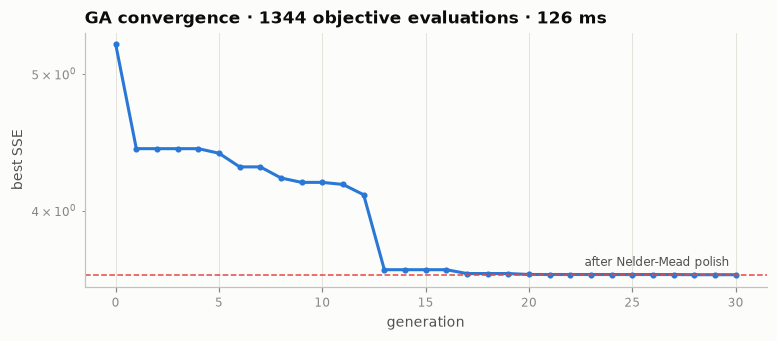

In [4]:
res = fit_window(t, y, bounds=cfg.bounds, ga_config=cfg.ga, rng=np.random.default_rng(SEED))
fit = res.fit
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(len(res.history)), res.history, color=viz.FIT, lw=2, marker="o", ms=3)
ax.axhline(fit.sse, color=viz.POS, ls="--", lw=1)
ax.annotate("after Nelder-Mead polish", (len(res.history) - 1, fit.sse), color=viz.INK_2, fontsize=8,
            xytext=(-4, 6), textcoords="offset points", ha="right")
ax.set_yscale("log"); ax.set_xlabel("generation"); ax.set_ylabel("best SSE")
ax.set_title(f"GA convergence · {res.n_evals} objective evaluations · {res.elapsed_ms:.0f} ms")
plt.show()

In [5]:
params = pd.Series(fit.to_dict())
params["tc_date"] = years_to_date(fit.tc).date()
params.to_frame("value")

,value
t1,2022.473648
t2,2024.461328
tc,2024.647666
m,0.555345
omega,7.237189
A,5.516694
B,-1.840324
C1,0.167418
C2,0.129962
sse,3.600132


## Fitted curve and residuals

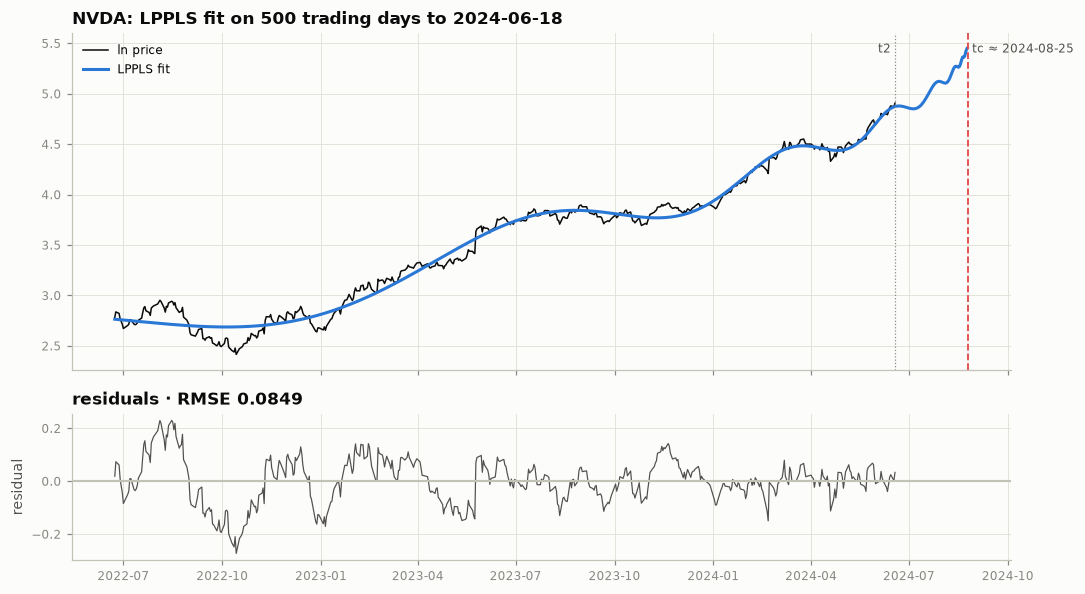

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
viz.fit_overlay(px.index, y, fit, ax=a1, title=f"{TICKER}: LPPLS fit on {WINDOW} trading days to {END}")
resid = y - fit.predict(t)
a2.plot(px.index, resid, color=viz.INK_2, lw=0.8); a2.axhline(0, color=viz.AXIS)
a2.set_ylabel("residual"); a2.set_title(f"residuals · RMSE {fit.rmse:.4f}")
fig.tight_layout()

## Qualification checklist (Sornette et al. 2015)

In [7]:
c = check(fit, cfg.filters)
f = cfg.filters
rules = {"m": f"{f.m_min} ≤ m ≤ {f.m_max}", "omega": f"{f.omega_min} ≤ ω ≤ {f.omega_max}",
         "tc": f"t2 − {f.tc_before}·dt ≤ tc ≤ t2 + {f.tc_after}·dt", "damping": f"D ≥ {f.damping_min}",
         "oscillations": f"O ≥ {f.oscillations_min}", "finite": "finite SSE", "rmse": "optional RMSE cap"}
values = {"m": fit.m, "omega": fit.omega, "tc": years_to_date(fit.tc).date(), "damping": fit.damping,
          "oscillations": fit.n_oscillations, "finite": fit.sse, "rmse": fit.rmse}
pd.DataFrame({"rule": rules, "value": values, "pass": {k: "✔ pass" if c[k] else "✘ fail" for k in rules}})

,rule,value,pass
m,0.1 ≤ m ≤ 0.9,0.555345,✔ pass
omega,2.0 ≤ ω ≤ 25.0,7.237189,✔ pass
tc,t2 − 0.05·dt ≤ tc ≤ t2 + 0.2·dt,2024-08-25,✔ pass
damping,D ≥ 0.5,0.666304,✔ pass
oscillations,O ≥ 2.5,5.659587,✔ pass
finite,finite SSE,3.600132,✔ pass
rmse,optional RMSE cap,0.084854,✔ pass


In [8]:
display(Markdown(f"**Qualified: {'yes' if c['qualified'] else 'no'}** · "
                 f"{'positive bubble (B < 0)' if fit.B < 0 else 'negative bubble (B > 0)'}"))

**Qualified: yes** · positive bubble (B < 0)

## Sensitivity to the window start

A single window is fragile. The indicator therefore fits *many* windows ending on
the same date; below, the critical time estimated for each window length.

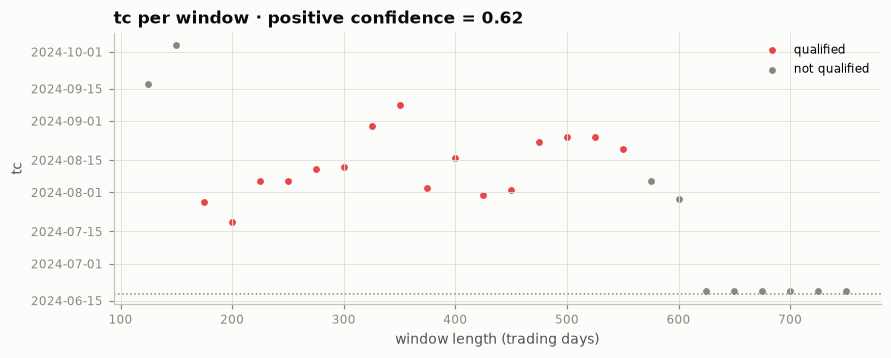

In [9]:
from lppl.model.indicator import scan_date
full = db.load_prices(engine, TICKER, end=END)["adj_close"].dropna()
recs = pd.DataFrame(scan_date(pd.DatetimeIndex(full.index), np.log(full.to_numpy()), len(full) - 1,
                              cfg.scan_settings(), cfg.seed, TICKER))
fig, ax = plt.subplots(figsize=(9, 3.2))
for q, color, lab in [(True, viz.POS, "qualified"), (False, viz.MUTED, "not qualified")]:
    d = recs[recs.qualified == q]
    ax.scatter(d["window_len"], pd.to_datetime(d["tc_date"]), color=color, s=36, label=lab,
               edgecolor=viz.SURFACE, linewidth=1.5)
ax.axhline(pd.Timestamp(END), color=viz.MUTED, ls=":", lw=1)
ax.set_xlabel("window length (trading days)"); ax.set_ylabel("tc"); ax.legend()
ax.set_title(f"tc per window · positive confidence = {((recs.qualified) & (recs.sign > 0)).mean():.2f}")
plt.show()